# Base: VGG16 em subconjuntos do CIFAR-100

Notebook base do projeto de interpretabilidade:

1. Carrega o CIFAR-100 (torchvision).
2. Seleciona um subconjunto de classes e remapeia os rótulos para `0..K-1`.
3. Treina uma VGG16 (CPU ou GPU).
4. Avalia no conjunto de teste e salva o checkpoint.

**Como usar:** edite apenas a célula abaixo e rode tudo (*Run All*).

In [11]:
# ======================= CONFIGURAÇÃO DO EXPERIMENTO =======================
USUARIO = "alvaro"         # seu nome
TESTE = "teste01"          # nome do teste/experimento

# Classes do CIFAR-100 a usar. Aceita:
#   - lista de nomes:   ["apple", "orange", "pear"]
#   - lista de índices: [0, 53, 57]
#   - inteiro N:        sorteia N classes (usa SEED)
#   - None:             todas as 100 classes
CLASSES = ["apple", "orange", "pear"]

MODELO = "cifar"           # "cifar" (VGG16-BN 32x32, do zero) | "imagenet" (VGG16-BN pré-treinada)
EPOCAS = 5
DISPOSITIVO = "auto"       # "auto" | "cuda" | "cuda:1" | "mps" | "cpu"
SEED = 42

# O modelo é salvo em ./USUARIO/TESTE/<nomes_das_classes>/
# ==========================================================================

<details><summary>Nomes das 100 classes do CIFAR-100 (índice: nome)</summary>

0: apple  
1: aquarium_fish  
2: baby  
3: bear  
4: beaver  
5: bed  
6: bee  
7: beetle  
8: bicycle  
9: bottle  
10: bowl  
11: boy  
12: bridge  
13: bus  
14: butterfly  
15: camel  
16: can  
17: castle  
18: caterpillar  
19: cattle  
20: chair  
21: chimpanzee  
22: clock  
23: cloud  
24: cockroach  
25: couch  
26: crab  
27: crocodile  
28: cup  
29: dinosaur  
30: dolphin  
31: elephant  
32: flatfish  
33: forest  
34: fox  
35: girl  
36: hamster  
37: house  
38: kangaroo  
39: keyboard  
40: lamp  
41: lawn_mower  
42: leopard  
43: lion  
44: lizard  
45: lobster  
46: man  
47: maple_tree  
48: motorcycle  
49: mountain  
50: mouse  
51: mushroom  
52: oak_tree  
53: orange  
54: orchid  
55: otter  
56: palm_tree  
57: pear  
58: pickup_truck  
59: pine_tree  
60: plain  
61: plate  
62: poppy  
63: porcupine  
64: possum  
65: rabbit  
66: raccoon  
67: ray  
68: road  
69: rocket  
70: rose  
71: sea  
72: seal  
73: shark  
74: shrew  
75: skunk  
76: skyscraper  
77: snail  
78: snake  
79: spider  
80: squirrel  
81: streetcar  
82: sunflower  
83: sweet_pepper  
84: table  
85: tank  
86: telephone  
87: television  
88: tiger  
89: tractor  
90: train  
91: trout  
92: tulip  
93: turtle  
94: wardrobe  
95: whale  
96: willow_tree  
97: wolf  
98: woman  
99: worm  

</details>

---

*Daqui para baixo não é preciso editar nada.*

## 1. Imports

In [12]:
import json
import random
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, models, transforms
from tqdm.auto import tqdm

print("torch", torch.__version__)

torch 2.15.0+cu132


## 2. Configuração interna

Junta a configuração do topo com os hiperparâmetros padrão.

**Modelo**:
- `"cifar"`: VGG16-BN adaptada a 32×32 (5 blocos conv, classificador 512→K), treinada do zero.
- `"imagenet"`: `torchvision.models.vgg16_bn` com pesos ImageNet e o último linear trocado para K saídas.
  Usa imagens redimensionadas para 224×224 (bem mais lento).

In [13]:
CFG = dict(
    usuario=USUARIO,
    teste=TESTE,
    classes=CLASSES,
    seed=SEED,
    data_dir="data",

    # --- dados ---
    val_frac=0.1,        # fração do treino separada para validação
    img_size=224 if MODELO == "imagenet" else 32,
    augment=True,
    batch_size=128,
    num_workers=4,

    # --- modelo ---
    model_variant=MODELO,
    dropout=0.5,

    # --- treino ---
    epochs=EPOCAS,
    lr=0.01 if MODELO == "imagenet" else 0.05,   # SGD (fine-tuning usa lr menor)
    momentum=0.9,
    weight_decay=5e-4,
    label_smoothing=0.0,
    amp=True,            # mixed precision (só tem efeito em CUDA)

    # --- dispositivo ---
    device=DISPOSITIVO,
)
for campo, valor in (("USUARIO", USUARIO), ("TESTE", TESTE)):
    if not str(valor).strip() or any(c in str(valor) for c in r'/\:*?"<>|'):
        raise ValueError(f"{campo} inválido para nome de pasta: {valor!r}")

## 3. Reprodutibilidade e dispositivo

In [14]:
def set_seed(seed: int):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


def get_device(pref: str = "auto") -> torch.device:
    if pref != "auto":
        return torch.device(pref)
    if torch.cuda.is_available():
        return torch.device("cuda")
    if getattr(torch.backends, "mps", None) and torch.backends.mps.is_available():
        return torch.device("mps")
    return torch.device("cpu")


set_seed(CFG["seed"])
device = get_device(CFG["device"])
use_amp = CFG["amp"] and device.type == "cuda"

if device.type == "cuda":
    torch.backends.cudnn.benchmark = True
    print("GPU:", torch.cuda.get_device_name(device))
print("device:", device, "| AMP:", use_amp)

device: cpu | AMP: False


## 4. CIFAR-100 e seleção de classes

In [15]:
CIFAR100_MEAN = (0.5071, 0.4865, 0.4409)
CIFAR100_STD = (0.2673, 0.2564, 0.2762)
IMAGENET_MEAN = (0.485, 0.456, 0.406)
IMAGENET_STD = (0.229, 0.224, 0.225)

# Dataset "cru" só para obter a lista de nomes e os rótulos.
_raw_train = datasets.CIFAR100(CFG["data_dir"], train=True, download=True)
ALL_CLASSES = _raw_train.classes  # 100 nomes, em ordem de índice


def resolve_classes(spec, all_classes, seed=0):
    """Converte a especificação de classes em uma lista ordenada de índices originais."""
    if spec is None:
        return list(range(len(all_classes)))
    if isinstance(spec, int):
        rng = random.Random(seed)
        return sorted(rng.sample(range(len(all_classes)), spec))
    idxs = []
    for c in spec:
        if isinstance(c, str):
            if c not in all_classes:
                raise ValueError(f"Classe desconhecida: {c!r}")
            idxs.append(all_classes.index(c))
        else:
            if not 0 <= int(c) < len(all_classes):
                raise ValueError(f"Índice fora do intervalo: {c}")
            idxs.append(int(c))
    if len(set(idxs)) != len(idxs):
        raise ValueError("Classes repetidas na seleção")
    return sorted(idxs)


selected = resolve_classes(CFG["classes"], ALL_CLASSES, CFG["seed"])
class_names = [ALL_CLASSES[i] for i in selected]
orig_to_new = {orig: new for new, orig in enumerate(selected)}
NUM_CLASSES = len(selected)

print(f"{NUM_CLASSES} classes:")
for new, orig in enumerate(selected):
    print(f"  {new:>3} <- {orig:>3}  {ALL_CLASSES[orig]}")

3 classes:
    0 <-   0  apple
    1 <-  53  orange
    2 <-  57  pear


### Transforms e splits

Os índices de treino/validação são estratificados por classe. Treino e validação usam
instâncias diferentes do dataset para que a validação não receba augmentation.

In [16]:
mean, std = (IMAGENET_MEAN, IMAGENET_STD) if CFG["model_variant"] == "imagenet" else (CIFAR100_MEAN, CIFAR100_STD)
size = CFG["img_size"]

resize = [transforms.Resize(size, antialias=True)] if size != 32 else []
train_tf = transforms.Compose(
    resize
    + ([transforms.RandomCrop(size, padding=size // 8), transforms.RandomHorizontalFlip()] if CFG["augment"] else [])
    + [transforms.ToTensor(), transforms.Normalize(mean, std)]
)
eval_tf = transforms.Compose(resize + [transforms.ToTensor(), transforms.Normalize(mean, std)])

target_tf = lambda y: orig_to_new[y]

train_full = datasets.CIFAR100(CFG["data_dir"], train=True, transform=train_tf, target_transform=target_tf)
val_full = datasets.CIFAR100(CFG["data_dir"], train=True, transform=eval_tf, target_transform=target_tf)
test_full = datasets.CIFAR100(CFG["data_dir"], train=False, transform=eval_tf, target_transform=target_tf)


def split_indices(targets, selected, val_frac, seed):
    rng = np.random.default_rng(seed)
    targets = np.asarray(targets)
    tr, va = [], []
    for c in selected:
        idx = np.flatnonzero(targets == c)
        rng.shuffle(idx)
        n_val = int(round(len(idx) * val_frac))
        va.extend(idx[:n_val].tolist())
        tr.extend(idx[n_val:].tolist())
    return sorted(tr), sorted(va)


train_idx, val_idx = split_indices(train_full.targets, selected, CFG["val_frac"], CFG["seed"])
test_idx = np.flatnonzero(np.isin(test_full.targets, selected)).tolist()

train_ds = Subset(train_full, train_idx)
val_ds = Subset(val_full, val_idx)
test_ds = Subset(test_full, test_idx)
print(f"treino: {len(train_ds)} | val: {len(val_ds)} | teste: {len(test_ds)}")

loader_kw = dict(
    batch_size=CFG["batch_size"],
    num_workers=CFG["num_workers"],
    pin_memory=device.type == "cuda",
    persistent_workers=CFG["num_workers"] > 0,
)
train_loader = DataLoader(train_ds, shuffle=True, drop_last=False, **loader_kw)
val_loader = DataLoader(val_ds, shuffle=False, **loader_kw)
test_loader = DataLoader(test_ds, shuffle=False, **loader_kw)

treino: 1350 | val: 150 | teste: 300


### Amostras

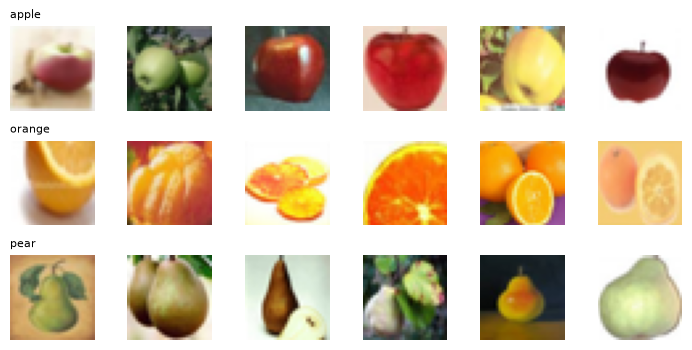

In [17]:
def denorm(x):
    m = torch.tensor(mean).view(3, 1, 1)
    s = torch.tensor(std).view(3, 1, 1)
    return (x * s + m).clamp(0, 1)


n_show = min(NUM_CLASSES, 10)
fig, axes = plt.subplots(n_show, 6, figsize=(6 * 1.2, n_show * 1.2))
axes = np.atleast_2d(axes)
by_class = {k: [] for k in range(n_show)}
for i in val_idx:
    x, y = val_full[i]
    if y < n_show and len(by_class[y]) < 6:
        by_class[y].append(x)
    if all(len(v) == 6 for v in by_class.values()):
        break
for r in range(n_show):
    for c in range(6):
        ax = axes[r, c]
        ax.axis("off")
        if c < len(by_class[r]):
            ax.imshow(denorm(by_class[r][c]).permute(1, 2, 0))
    axes[r, 0].set_title(class_names[r], fontsize=8, loc="left")
plt.tight_layout()
plt.show()

## 5. Modelo VGG16

In [18]:
VGG16_CFG = [64, 64, "M", 128, 128, "M", 256, 256, 256, "M", 512, 512, 512, "M", 512, 512, 512, "M"]


class VGG16CIFAR(nn.Module):
    """VGG16 com BatchNorm para entradas 32x32 (após 5 poolings o mapa fica 1x1x512)."""

    def __init__(self, num_classes: int, dropout: float = 0.5):
        super().__init__()
        layers, in_ch = [], 3
        for v in VGG16_CFG:
            if v == "M":
                layers.append(nn.MaxPool2d(2, 2))
            else:
                layers += [nn.Conv2d(in_ch, v, 3, padding=1), nn.BatchNorm2d(v), nn.ReLU(inplace=True)]
                in_ch = v
        self.features = nn.Sequential(*layers)
        self.avgpool = nn.AdaptiveAvgPool2d(1)
        self.classifier = nn.Sequential(
            nn.Dropout(dropout),
            nn.Linear(512, 512),
            nn.ReLU(inplace=True),
            nn.Dropout(dropout),
            nn.Linear(512, num_classes),
        )
        self._init_weights()

    def _init_weights(self):
        for m in self.modules():
            if isinstance(m, nn.Conv2d):
                nn.init.kaiming_normal_(m.weight, mode="fan_out", nonlinearity="relu")
                nn.init.zeros_(m.bias)
            elif isinstance(m, nn.BatchNorm2d):
                nn.init.ones_(m.weight)
                nn.init.zeros_(m.bias)
            elif isinstance(m, nn.Linear):
                nn.init.normal_(m.weight, 0, 0.01)
                nn.init.zeros_(m.bias)

    def forward(self, x):
        x = self.features(x)
        x = self.avgpool(x).flatten(1)
        return self.classifier(x)


def build_model(variant: str, num_classes: int, dropout: float = 0.5) -> nn.Module:
    if variant == "cifar":
        return VGG16CIFAR(num_classes, dropout)
    if variant == "imagenet":
        m = models.vgg16_bn(weights=models.VGG16_BN_Weights.IMAGENET1K_V1, dropout=dropout)
        m.classifier[-1] = nn.Linear(m.classifier[-1].in_features, num_classes)
        return m
    raise ValueError(f"model_variant desconhecido: {variant}")


model = build_model(CFG["model_variant"], NUM_CLASSES, CFG["dropout"]).to(device)
n_params = sum(p.numel() for p in model.parameters())
print(f"{CFG['model_variant']} | {n_params / 1e6:.2f}M parâmetros")

cifar | 14.99M parâmetros


## 6. Treino

In [19]:
def run_epoch(model, loader, criterion, optimizer=None, scaler=None, desc=""):
    """Uma passada pelo loader. Treina se `optimizer` for dado; senão só avalia."""
    train = optimizer is not None
    model.train(train)
    total_loss, correct, n = 0.0, 0, 0
    with torch.set_grad_enabled(train):
        for x, y in tqdm(loader, desc=desc, leave=False):
            x = x.to(device, non_blocking=True)
            y = y.to(device, non_blocking=True)
            with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=use_amp):
                logits = model(x)
                loss = criterion(logits, y)
            if train:
                optimizer.zero_grad(set_to_none=True)
                scaler.scale(loss).backward()
                scaler.step(optimizer)
                scaler.update()
            total_loss += loss.item() * y.size(0)
            correct += (logits.argmax(1) == y).sum().item()
            n += y.size(0)
    return total_loss / n, correct / n


criterion = nn.CrossEntropyLoss(label_smoothing=CFG["label_smoothing"])
optimizer = torch.optim.SGD(
    model.parameters(), lr=CFG["lr"], momentum=CFG["momentum"],
    weight_decay=CFG["weight_decay"], nesterov=True,
)
scheduler = torch.optim.lr_scheduler.OneCycleLR(
    optimizer, max_lr=CFG["lr"], epochs=CFG["epochs"], steps_per_epoch=1, pct_start=0.15,
)  # passo por época
scaler = torch.amp.GradScaler(device.type, enabled=use_amp)

def classes_dirname(names, max_len=150):
    """Nome da pasta a partir das classes (ordenadas por índice, unidas por '-').
    Se ficar longo demais para o sistema de arquivos, usa '<K>classes_<hash>'."""
    name = "-".join(names)
    if len(name) <= max_len:
        return name
    import hashlib
    return f"{len(names)}classes_{hashlib.sha1(name.encode()).hexdigest()[:10]}"


run_dir = Path(".") / CFG["usuario"] / CFG["teste"] / classes_dirname(class_names)
run_dir.mkdir(parents=True, exist_ok=True)
ckpt_path = run_dir / "model.pt"
with open(run_dir / "config.json", "w") as f:
    json.dump({**CFG, "selected": selected, "class_names": class_names}, f, indent=2, ensure_ascii=False)
print("salvando em:", run_dir.resolve())

salvando em: /home/alvie/Desktop/Mestrado/projeto-interpretabilidade/alvaro/teste01/apple-orange-pear


In [20]:
history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": [], "lr": []}
best_val = -1.0

for epoch in range(1, CFG["epochs"] + 1):
    t0 = time.time()
    lr = optimizer.param_groups[0]["lr"]
    tr_loss, tr_acc = run_epoch(model, train_loader, criterion, optimizer, scaler, desc=f"ep {epoch} treino")
    va_loss, va_acc = run_epoch(model, val_loader, criterion, desc=f"ep {epoch} val")
    scheduler.step()

    for k, v in zip(history, (tr_loss, tr_acc, va_loss, va_acc, lr)):
        history[k].append(v)

    flag = ""
    if va_acc > best_val:
        best_val = va_acc
        torch.save(
            {
                "model_state": model.state_dict(),
                "cfg": CFG,
                "selected": selected,
                "class_names": class_names,
                "epoch": epoch,
                "val_acc": va_acc,
            },
            ckpt_path,
        )
        flag = " *"
    print(
        f"ep {epoch:>3}/{CFG['epochs']} | lr {lr:.4f} | "
        f"treino {tr_loss:.3f} / {tr_acc:.3f} | val {va_loss:.3f} / {va_acc:.3f} | "
        f"{time.time() - t0:.0f}s{flag}"
    )

with open(run_dir / "history.json", "w") as f:
    json.dump(history, f, indent=2)
print(f"melhor val acc: {best_val:.4f} -> {ckpt_path}")

ep   1/5 | lr 0.0496 | treino 1.007 / 0.443 | val 0.930 / 0.493 | 17s *


ep   2/5 | lr 0.0401 | treino 0.754 / 0.664 | val 0.658 / 0.727 | 16s *


ep   3/5 | lr 0.0227 | treino 0.581 / 0.762 | val 0.461 / 0.820 | 17s *


ep   4/5 | lr 0.0065 | treino 0.526 / 0.790 | val 0.405 / 0.827 | 17s *


ep   5/5 | lr 0.0000 | treino 0.508 / 0.800 | val 0.440 / 0.813 | 16s
melhor val acc: 0.8267 -> alvaro/teste01/apple-orange-pear/model.pt


### Curvas

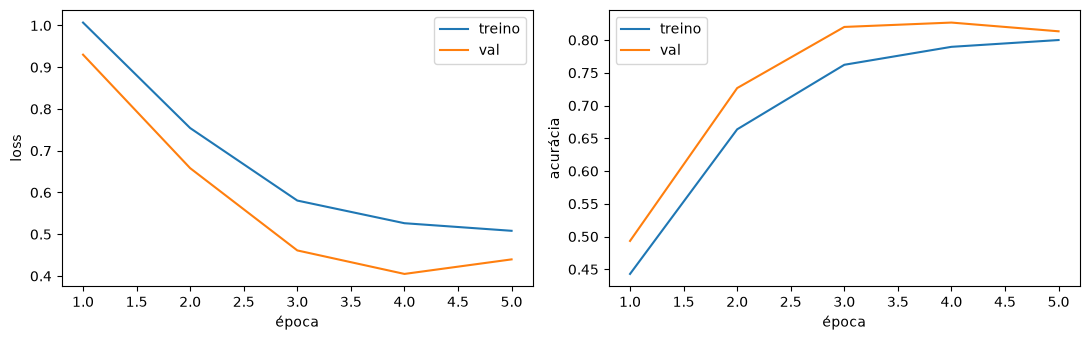

In [21]:
ep = range(1, len(history["train_loss"]) + 1)
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.5))
a1.plot(ep, history["train_loss"], label="treino")
a1.plot(ep, history["val_loss"], label="val")
a1.set_xlabel("época"); a1.set_ylabel("loss"); a1.legend()
a2.plot(ep, history["train_acc"], label="treino")
a2.plot(ep, history["val_acc"], label="val")
a2.set_xlabel("época"); a2.set_ylabel("acurácia"); a2.legend()
plt.tight_layout()
plt.show()

## 7. Avaliação no teste (melhor checkpoint)

In [22]:
ckpt = torch.load(ckpt_path, map_location=device)
model.load_state_dict(ckpt["model_state"])
print(f"checkpoint da época {ckpt['epoch']} (val acc {ckpt['val_acc']:.4f})")


@torch.no_grad()
def predict(model, loader):
    model.eval()
    ys, ps = [], []
    for x, y in loader:
        logits = model(x.to(device, non_blocking=True))
        ps.append(logits.argmax(1).cpu())
        ys.append(y)
    return torch.cat(ys).numpy(), torch.cat(ps).numpy()


y_true, y_pred = predict(model, test_loader)
test_acc = float((y_true == y_pred).mean())
per_class = {name: float((y_pred[y_true == k] == k).mean()) for k, name in enumerate(class_names)}
print(f"acurácia no teste: {test_acc:.4f}\n")
for k, name in enumerate(class_names):
    print(f"  {name:<15} {per_class[name]:.3f}  (n={(y_true == k).sum()})")

with open(run_dir / "test_metrics.json", "w") as f:
    json.dump({"test_acc": test_acc, "per_class": per_class, "best_epoch": ckpt["epoch"],
               "val_acc": ckpt["val_acc"]}, f, indent=2)

checkpoint da época 4 (val acc 0.8267)
acurácia no teste: 0.8167

  apple           0.750  (n=100)
  orange          0.900  (n=100)
  pear            0.800  (n=100)


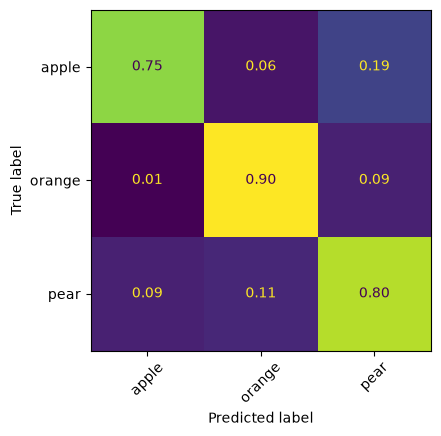

In [23]:
from sklearn.metrics import ConfusionMatrixDisplay

if NUM_CLASSES <= 20:
    fig, ax = plt.subplots(figsize=(0.5 * NUM_CLASSES + 3, 0.5 * NUM_CLASSES + 3))
    ConfusionMatrixDisplay.from_predictions(
        y_true, y_pred, display_labels=class_names, normalize="true",
        values_format=".2f", xticks_rotation=45, ax=ax, colorbar=False,
    )
    plt.tight_layout()
    plt.show()
else:
    print("Muitas classes para exibir a matriz de confusão.")